# Recuperación de comunidades dinámicas sobre redes usando datos simulados y el modelo DSBM 

## Formulación

Supongamos que tenemos una secuencia de redes binarias y no dirigidas observadas
$\mathbf{A}_1, \mathbf{A}_2, \ldots, \mathbf{A}_T \in \{0,1\}^{n\times n}$,
donde $n$ es el número de nodos y además
$\mathbf{A}_t = \mathbf{A}_{t}^{\top}$ para todo
$t\in\{1,\ldots,T\}$.

Queremos modelar simultáneamente la estructura de cada una de las redes, la
pertenencia de los nodos a comunidades y la evolución temporal de dichas
comunidades. Para esto, agregamos al modelo de bloques estocásticos una
transición Markoviana que permita describir la evolución temporal de la
pertenencia de los nodos a las comunidades.



Sea $K$ el número de comunidades y sea
$Z_{it}\in\{1,\ldots,K\}$ la variable latente que indica la comunidad a la
que pertenece el nodo $i$ en el tiempo $t$. Denotamos por
$\mathbf{Z}_t=(Z_{1t},\ldots,Z_{nt})^{\top}$ el vector de asignaciones comunitarias
en el tiempo $t$.

En primer lugar, suponemos que la asignación comunitaria inicial de cada
nodo es independiente y sigue una distribución categórica con probabilidades
$\boldsymbol{\pi}=(\pi_1,\ldots,\pi_K)$, de modo que

\begin{align*}
Z_{i1}\mid\boldsymbol{\pi}
&\sim \operatorname{Categorical}(\boldsymbol{\pi}),
\qquad i=1,\ldots,n,
\end{align*}

donde $\sum_{k=1}^K\pi_k=1$.

Para modelar la evolución temporal de las comunidades, suponemos que las
asignaciones de cada nodo siguen una cadena de Markov de primer orden.
Específicamente, si $Z_{it}=k$, entonces la probabilidad de que el nodo
pase a la comunidad $l$ en el siguiente instante está determinada por la
matriz de transición $\mathbf{P}=(P_{kl})_{k,l=1}^K$. Por tanto,

\begin{align*}
Z_{i,t+1}\mid Z_{it}=k,\mathbf{P}
&\sim \operatorname{Categorical}
\left(P_{k1},\ldots,P_{kK}\right),
\end{align*}

donde

\begin{align*}
P_{kl}
&=P(Z_{i,t+1}=l\mid Z_{it}=k),
\end{align*}

y cada fila de $\mathbf{P}$ satisface

\begin{align*}
\sum_{l=1}^K P_{kl}=1.
\end{align*}

De esta manera, la matriz $\mathbf{P}$ permite introducir dependencia
temporal en las asignaciones comunitarias. Por ejemplo, valores grandes de
$P_{kk}$ representan una mayor probabilidad de que un nodo permanezca en la
misma comunidad entre dos instantes consecutivos, mientras que los valores
$P_{kl}$ con $k\neq l$ representan la probabilidad de transición entre
comunidades diferentes.

Para completar el modelo, suponemos que cada fila de la matriz de transición
posee una distribución a priori Dirichlet,

\begin{align*}
\mathbf{P}_{k\cdot}
&\sim \operatorname{Dirichlet}
\left(\alpha_{k1},\ldots,\alpha_{kK}\right),
\qquad k=1,\ldots,K.
\end{align*}

Esta elección permite utilizar la conjugación entre las distribuciones
Dirichlet y categórica durante el procedimiento de inferencia.

Condicionalmente a las asignaciones comunitarias, suponemos que la
probabilidad de existencia de una conexión entre dos nodos depende
únicamente de las comunidades a las que pertenecen. Sea
$\theta_{kl}$ la probabilidad de conexión entre un nodo perteneciente a la
comunidad $k$ y otro perteneciente a la comunidad $l$. Entonces, para
$i<j$,

\begin{align*}
A_{ijt}\mid Z_{ir}=k,Z_{jt}=l,\boldsymbol{\Theta}
&\sim \operatorname{Bernoulli}(\theta_{kl}),
\end{align*}

donde $\boldsymbol{\Theta}=(\theta_{kl})$ es la matriz de parámetros de
conectividad.

Como las redes son no dirigidas, imponemos la condición

\begin{align*}
\theta_{kl}=\theta_{lk}.
\end{align*}

En consecuencia, $\theta_{kk}$ representa la probabilidad de conexión entre
dos nodos pertenecientes a la misma comunidad, mientras que
$\theta_{kl}$, para $k\neq l$, representa la probabilidad de conexión entre
dos comunidades diferentes.

Para los parámetros de conectividad utilizamos una distribución a priori
Beta,

\begin{align*}
\theta_{kl}
&\sim \operatorname{Beta}(a,b).
\end{align*}

La estructura completa del modelo puede resumirse mediante la siguiente
factorización jerárquica:

\begin{align}
\boldsymbol{\pi}
&\sim \operatorname{Dirichlet}(\boldsymbol{\gamma}),\\
\mathbf{P}_{k\cdot}
&\sim \operatorname{Dirichlet}(\boldsymbol{\alpha}_k),
\qquad k=1,\ldots,K,\\
\theta_{kl}
&\sim \operatorname{Beta}(a,b),\\
Z_{i1}\mid\boldsymbol{\pi}
&\sim \operatorname{Categorical}(\boldsymbol{\pi}),\\
Z_{i,t+1}\mid Z_{it},\mathbf{P}
&\sim \operatorname{Categorical}(\mathbf{P}_{Z_{it},\cdot}),\\
A_{ijr}\mid Z_{it},Z_{jt},\boldsymbol{\Theta}
&\sim \operatorname{Bernoulli}
\left(\theta_{Z_{it},Z_{jt}}\right).
\end{align}

La introducción de la cadena de Markov permite, por tanto, separar dos
fuentes de información para determinar la comunidad de un nodo. Por una
parte, la estructura de la red proporciona información sobre la comunidad
a través de los patrones de conectividad. Por otra parte, la dinámica
temporal proporciona información a través de las comunidades a las que el
nodo pertenecía en instantes anteriores y posteriores.



**Inferencia bayesiana**

El objetivo de la inferencia es obtener la distribución posterior conjunta
de las asignaciones comunitarias y de los parámetros del modelo,

\begin{align*}
p(\boldsymbol{\pi},\mathbf{P},\boldsymbol{\Theta},\mathbf{Z}
\mid \mathbf{A}_1,\ldots,\mathbf{A}_T).
\end{align*}

Utilizando la regla de Bayes, esta distribución puede escribirse,
salvo una constante de normalización, como

\begin{align*}
&p(\boldsymbol{\pi},\mathbf{P},\boldsymbol{\Theta},\mathbf{Z}
\mid \mathbf{A}_1,\ldots,\mathbf{A}_T)\\
&\qquad\propto
p(\boldsymbol{\pi})p(\mathbf{P})p(\boldsymbol{\Theta})
p(\mathbf{Z}\mid\boldsymbol{\pi},\mathbf{P})
p(\mathbf{A}_1,\ldots,\mathbf{A}_T
\mid\mathbf{Z},\boldsymbol{\Theta}).
\end{align*}

La inferencia de las comunidades es el principal problema computacional,
puesto que las variables $\mathbf{Z}$ son latentes. Para resolverlo,
utilizamos un algoritmo de Monte Carlo basado en cadenas de Markov
(MCMC), específicamente un muestreador de Gibbs.

La idea fundamental del muestreador de Gibbs consiste en actualizar
iterativamente cada conjunto de parámetros a partir de su distribución
condicional completa. Debido a la conjugación de las distribuciones
Dirichlet--categórica y Beta--Bernoulli, las distribuciones condicionales de
los parámetros $\boldsymbol{\pi}$, $\mathbf{P}$ y $\boldsymbol{\Theta}$
tienen formas conocidas.

Para obtener estas distribuciones condicionales, definimos primero el número
de nodos que pertenecen a cada comunidad en el tiempo inicial,

\begin{align*}
N_k^{(1)}
&=
\sum_{i=1}^{n}\mathbb{I}(Z_{i1}=k).
\end{align*}

Asimismo, definimos el número de transiciones de la comunidad $k$ hacia la
comunidad $l$ a lo largo de toda la secuencia temporal,

\begin{align*}
N_{kl}
&=
\sum_{i=1}^{n}\sum_{t=1}^{T-1}
\mathbb{I}(Z_{it}=k,Z_{i,t+1}=l).
\end{align*}

Finalmente, para cada par de comunidades definimos el número de conexiones
observadas entre ellas,

\begin{align*}
M_{kl}
&=
\sum_{t=1}^{T}\sum_{1\leq i<j\leq n}
\mathbb{I}(Z_{it}=k,Z_{jt}=l)A_{ijt},
\end{align*}

y el número de pares de nodos sin conexión,

\begin{align*}
\overline{M}_{kl}
&=
\sum_{t=1}^{T}\sum_{1\leq i<j\leq n}
\mathbb{I}(Z_{it}=k,Z_{jt}=l)(1-A_{ijt}).
\end{align*}

Por conjugación, la distribución posterior de las probabilidades iniciales
es

\begin{align*}
\boldsymbol{\pi}\mid\mathbf{Z}
&\sim
\operatorname{Dirichlet}
\left(
\gamma_1+N_1^{(1)},\ldots,
\gamma_K+N_K^{(1)}
\right).
\end{align*}

De manera análoga, para cada comunidad $k$, la distribución posterior de
la fila $k$ de la matriz de transición es

\begin{align*}
\mathbf{P}_{k\cdot}\mid\mathbf{Z}
&\sim
\operatorname{Dirichlet}
\left(
\alpha_{k1}+N_{k1},
\ldots,
\alpha_{kK}+N_{kK}
\right).
\end{align*}

Finalmente, la distribución posterior de los parámetros de conectividad es

\begin{align*}
\theta_{kl}\mid\mathbf{Z},\mathbf{A}
&\sim
\operatorname{Beta}
\left(
a+M_{kl},
b+\overline{M}_{kl}
\right).
\end{align*}

El paso más importante del algoritmo corresponde a actualizar las
asignaciones comunitarias $Z_{it}$. Para un nodo $i$ en un instante
intermedio $1<t<T$, la distribución condicional completa de $Z_{it}$
combina la información proveniente de la dinámica temporal con la
información proveniente de la red observada en el instante $t$.

Para $k\in\{1,\ldots,K\}$,

\begin{align*}
&p(Z_{ir}=k\mid -)\\
&\qquad\propto
P_{Z_{i,t-1},k}
P_{k,Z_{i,t+1}}
\prod_{j\,:\,j\neq i}^{n}
\theta_{k,Z_{jt}}^{A_{ijt}}
(1-\theta_{k,Z_{jt}})^{1-A_{ijt}}.
\end{align*}

La primera parte,

\begin{align*}
P_{Z_{i,t-1},k},
\end{align*}

representa la información proveniente del estado anterior del nodo. La
segunda,

\begin{align*}
P_{k,Z_{i,t+1}},
\end{align*}

incorpora la información del estado siguiente. Finalmente,

\begin{align*}
\prod_{j\,:\,j\neq i}^{n}
\theta_{k,Z_{jt}}^{A_{ijt}}
(1-\theta_{k,Z_{jt}})^{1-A_{ijt}}
\end{align*}

corresponde a la verosimilitud de las conexiones del nodo $i$ con el resto
de la red en el instante $t$, suponiendo que $i$ pertenece a la comunidad
$k$.

Por tanto, el muestreador de Gibbs actualiza alternativamente los
parámetros del modelo y las asignaciones latentes. Este procedimiento
permite obtener muestras de la distribución posterior y, a partir de ellas,
realizar inferencia sobre la estructura comunitaria y sobre la dinámica
temporal de las comunidades.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import logsumexp
from sklearn.metrics import adjusted_rand_score
import tqdm

## Generación de datos

In [2]:
# PARÁMETROS DEL EXPERIMENTO
# Número de nodos
N = 10
# Número de instantes temporales
T = 25
# Número de comunidades
K = 2
# Semilla para reproducibilidad
SEED = 0
rng = np.random.default_rng(SEED)

In [3]:
# PARÁMETROS VERDADEROS DEL MODELO
# ------------------------------------------------
# Distribución inicial de las comunidades
# ------------------------------------------------
pi_true = np.array([4/9, 5/9])
# ------------------------------------------------
# Matriz de transición de las comunidades
# ------------------------------------------------
# P[r, s] =
# P(Z_{i,t+1}=s | Z_{it}=r)
# La diagonal es grande, por lo que las comunidades
# presentan persistencia temporal.
# ------------------------------------------------
P_true = np.array([
    [0.90, 0.10],
    [0.15, 0.85]
])
# ------------------------------------------------
# Matriz Theta del SBM
# Theta[k, l] =
# P(A_ijt = 1 | Z_it=k, Z_jt=l)
Theta_true = np.array([
    [0.80, 0.15],
    [0.15, 0.70]
])


In [4]:
# GENERACIÓN DE LAS COMUNIDADES DINÁMICAS
def generate_communities(N, T, K, pi, P, rng):
    """
    Genera las asignaciones comunitarias Z.
    Parámetros
    ----------
    N : int
        Número de nodos.
    T : int
        Número de instantes temporales.
    K : int
        Número de comunidades.
    pi : array
        Distribución inicial sobre las comunidades.
    P : array (K x K)
        Matriz de transición de la cadena de Markov.
    rng : numpy random generator
        Generador aleatorio.
    Retorna
    -------
    Z : array (N x T)
        Z[i, t] es la comunidad del nodo i
        en el instante t.
    """
    # Matriz que almacenará las comunidades.
    # Z[i, t] ∈ {0, ..., K-1}
    Z = np.zeros((N, T), dtype=int)
    # Estado inicial
    for i in range(N):
        Z[i, 0] = rng.choice(K,p=pi)
    # Evolución temporal
    for t in range(1, T):
        for i in range(N):
            # Comunidad actual
            r = Z[i, t-1]
            # Distribución de la siguiente comunidad
            transition_probabilities = P[r]
            # Muestreamos la nueva comunidad
            Z[i, t] = rng.choice(K, p=transition_probabilities)
    return Z

In [5]:
# GENERACIÓN DE LAS REDES
def generate_networks(Z, Theta, rng):
    """
    Genera las matrices de adyacencia A_t.
    Se supone una red no dirigida sin auto-enlaces.
    A[i,j,t] ~ Bernoulli(Theta[Z[i,t], Z[j,t]])
    Parámetros
    ----------
    Z : array (N x T)
        Comunidades verdaderas.
    Theta : array (K x K)
        Probabilidades de conexión entre comunidades.
    rng : numpy random generator
    Retorna
    -------
    A : array (T x N x N)
        A[t,i,j] = 1 si existe una conexión
        entre i y j en el tiempo t.
    """
    N, T = Z.shape
    A = np.zeros((T, N, N), dtype=int)
    for t in range(T):
        for i in range(N):
            for j in range(i + 1, N):
                # Comunidades de los dos nodos
                k = Z[i, t]
                l = Z[j, t]
                # Probabilidad de conexión
                p = Theta[k, l]
                # Generamos la arista
                edge = rng.binomial(n=1, p=p)
                # Red no dirigida:
                A[t, i, j] = edge
                A[t, j, i] = edge
    return A


In [6]:
# GENERAMOS LOS DATOS
Z_true = generate_communities(
    N=N,
    T=T,
    K=K,
    pi=pi_true,
    P=P_true,
    rng=rng
)


A = generate_networks(
    Z=Z_true,
    Theta=Theta_true,
    rng=rng
)


print("Datos generados.")
print("Dimensión de A:", A.shape)
print("N =", N)
print("T =", T)
print("K =", K)




Datos generados.
Dimensión de A: (25, 10, 10)
N = 10
T = 25
K = 2


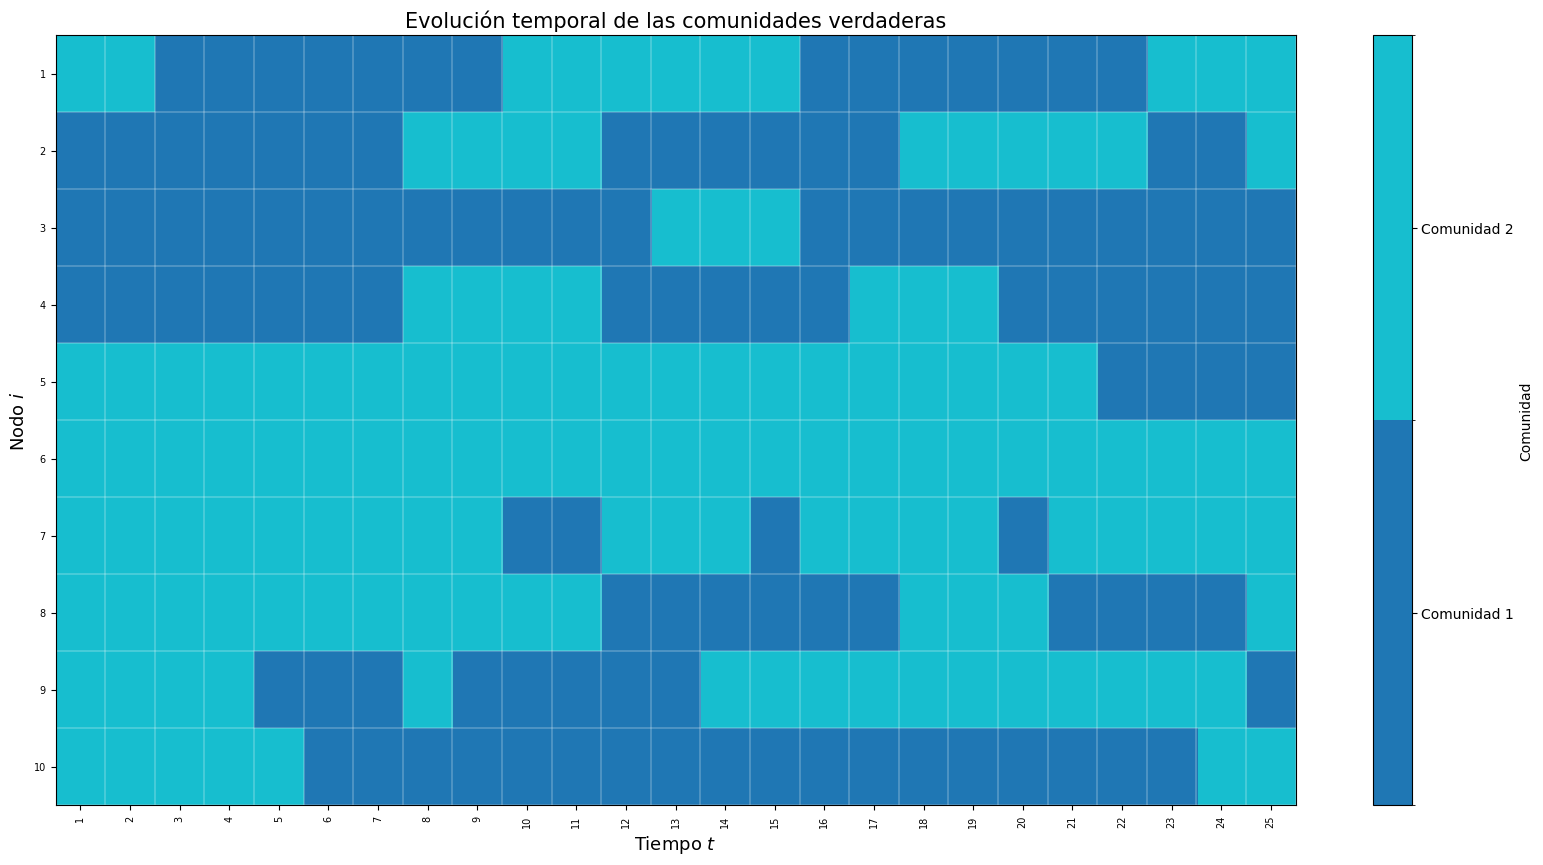

In [7]:
# VISUALIZACIÓN DE LA EVOLUCIÓN DE LAS COMUNIDADES
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

def plot_community_evolution(Z, title="Evolución temporal de las comunidades"):
    """
    Visualiza las asignaciones comunitarias Z_{it} como un mapa de calor.
    Parámetros
    ----------
    Z : np.ndarray
        Matriz de dimensiones (N, T), donde Z[i, t] representa
        la comunidad del nodo i en el tiempo t.
    title : str
        Título de la figura.
    """
    N, T = Z.shape
    # Número de comunidades
    K = len(np.unique(Z))
    # Definimos un mapa de colores discreto
    cmap = plt.get_cmap("tab10", K)
    # Los límites permiten que cada entero corresponda
    # exactamente a una comunidad.
    boundaries = np.arange(-0.5, K + 0.5, 1)
    norm = BoundaryNorm(boundaries, cmap.N)
    # Creamos la figura
    fig, ax = plt.subplots(figsize=(20, 10))
    # Mapa de calor
    # Z tiene:
    # filas    -> nodos
    # columnas -> tiempos
    im = ax.imshow(Z, aspect="auto", interpolation="none", cmap=cmap,norm=norm)
    # Eje X: tiempo
    ax.set_xlabel("Tiempo $t$", fontsize=13)
    ax.set_xticks(np.arange(T))
    ax.set_xticklabels(np.arange(1, T + 1), fontsize=7, rotation=90)
    # Eje Y: nodos
    ax.set_ylabel("Nodo $i$", fontsize=13)
    ax.set_yticks(np.arange(N))
    ax.set_yticklabels(np.arange(1, N + 1), fontsize=7)
    # Barra de color
    cbar = fig.colorbar(im,ax=ax,ticks=np.arange(K))
    cbar.set_label("Comunidad", fontsize=10)
    cbar.set_ticks(np.arange(K))
    cbar.set_ticklabels([f"Comunidad {k + 1}" for k in range(K)])
    # Título
    ax.set_title(title, fontsize=15)
    # Líneas de separación entre tiempos
    ax.set_xticks(np.arange(-0.5, T, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, N, 1), minor=True)
    ax.grid(which="minor", color="white", linestyle="-",linewidth=0.3)
    # No mostrar las etiquetas de los ticks menores
    ax.tick_params(which="minor", bottom=False, left=False)
    plt.show()

plot_community_evolution(Z_true, title="Evolución temporal de las comunidades verdaderas")

## Inferencia

In [8]:
# FUNCIONES AUXILIARES PARA GIBBS

def sample_categorical(probabilities, rng):
    """
    Muestra una categoría a partir de un vector
    de probabilidades.
    """

    probabilities = np.asarray(probabilities)

    return rng.choice(
        len(probabilities),
        p=probabilities
    )


In [9]:
# CÁLCULO DE LA PROBABILIDAD DE UNA ASIGNACIÓN Z
def log_probability_Z(i, t, k, Z, A, P, Theta, pi):
    """
    Calcula, salvo una constante, el logaritmo de
        P(Z_it = k | resto)
    utilizando tres fuentes de información:
        1. transición desde el pasado,
        2. transición hacia el futuro,
        3. estructura de la red.
    Es decir:
        posterior ∝ pasado × futuro × likelihood de red
    """
    N, T = Z.shape

    log_prob = 0.0
    if t == 0:
        probability = pi[k]
        if probability <= 0:
            return -np.inf
        log_prob += np.log(probability)
    # INFORMACIÓN TEMPORAL: PASADO
    if t > 0:
        previous_state = Z[i, t-1]
        probability = P[previous_state,k]
        # Evitamos log(0)
        if probability <= 0:
            return -np.inf
        log_prob += np.log(probability)
    # 2. INFORMACIÓN TEMPORAL: FUTURO
    if t < T - 1:
        next_state = Z[i, t+1]
        probability = P[k,next_state]
        if probability <= 0:
            return -np.inf
        log_prob += np.log(probability)
    # 3. INFORMACIÓN DE LA RED
    # El nodo i se conecta con todos los demás nodos.
    # Para cada j observamos:
    # A[i,j,t]
    # y conocemos temporalmente la asignación actual de j:
    # Z[j,t]
    # Si proponemos Z[i,t] = k, entonces:
    # P(A[i,j,t] | k, Z[j,t], Theta)
    # se obtiene mediante un Bernoulli.
    for j in range(N):
        # No existe auto-enlace
        if i == j:
            continue
        l = Z[j, t]
        p = Theta[k, l]
        edge = A[t, i, j]
        if edge == 1:
            if p <= 0:
                return -np.inf
            log_prob += np.log(p)
        else:
            if p >= 1:
                return -np.inf
            log_prob += np.log(1 - p)
    return log_prob

In [10]:
# ACTUALIZACIÓN GIBBS DE Z
def sample_Z(Z, A, P, Theta, pi, rng):
    """
    Actualiza todas las variables latentes Z_it
    mediante Gibbs sampling.
    Para cada nodo i y tiempo t:
        1. Probamos cada comunidad k.
        2. Calculamos log P(Z_it=k | resto).
        3. Normalizamos las probabilidades.
        4. Muestreamos una nueva comunidad.
    Retorna
    -------
    Z : array actualizado
    """
    N, T = Z.shape
    for i in range(N):
        for t in range(T):
            log_probs = np.zeros(K)
            # Calculamos la probabilidad de cada posible comunidad
            for k in range(K):
                log_probs[k] = log_probability_Z(i=i,t=t,k=k,Z=Z,A=A,P=P,Theta=Theta,pi=pi)
            # Normalización numéricamente estable
            # p_k = exp(log p_k) / sum_j exp(log p_j)
            # Utilizamos logsumexp para evitar problemas numéricos.
            normalization = logsumexp(log_probs)
            probabilities = np.exp(log_probs - normalization)
            # Muestreamos nueva comunidad
            Z[i, t] = rng.choice(K,p=probabilities)
    return Z



In [11]:
# CONTAR TRANSICIONES ENTRE COMUNIDADES
def transition_counts(Z, K):
    """
    Calcula los conteos:
        N_rs = número de transiciones r -> s
    a través de todos los nodos y tiempos.
    """
    N, T = Z.shape
    counts = np.zeros((K, K),dtype=int)
    for i in range(N):
        for t in range(T - 1):
            r = Z[i, t]
            s = Z[i, t+1]
            counts[r, s] += 1
    return counts

In [12]:
# ACTUALIZACIÓN DE P MEDIANTE CONJUGACIÓN
def sample_P(Z,alpha,rng):
    """
    Actualiza la matriz de transición P.
    Para cada comunidad r:
        P_r ~ Dirichlet(
            alpha_r + N_r1,
            ...,
            alpha_r + N_rK
        )
    Esto es exactamente la conjugación:
        Dirichlet + Multinomial.
    """
    counts = transition_counts(Z, K)
    P_new = np.zeros((K, K))
    for r in range(K):
        posterior_alpha = (alpha[r] + counts[r])
        P_new[r] = rng.dirichlet(posterior_alpha)
    return P_new

In [13]:
# CONTAR ENLACES POR BLOQUE
def block_counts(Z, A, K):
    """
    Calcula para cada par de comunidades (k,l):
        E_kl = número de enlaces
        F_kl = número de no-enlaces
    Se considera una red no dirigida y, por tanto,
    solamente utilizamos i < j.
    """
    N, T = Z.shape
    edges = np.zeros((K, K),dtype=int)
    non_edges = np.zeros((K, K),dtype=int)
    for t in range(T):
        for i in range(N):
            for j in range(i + 1, N):
                k = Z[i, t]
                l = Z[j, t]
                if A[t, i, j] == 1:
                    edges[k, l] += 1
                    # Como la red es no dirigida,
                    # (k,l) y (l,k) representan
                    # el mismo bloque.
                    if k != l:
                        edges[l, k] += 1
                else:
                    non_edges[k, l] += 1
                    if k != l:
                        non_edges[l, k] += 1
    return edges, non_edges

In [14]:
# ACTUALIZACIÓN DE THETA
def sample_Theta(Z, A, a_prior, b_prior, rng):
    """
    Actualiza Theta utilizando la conjugación:
        Beta + Bernoulli.
    Para cada bloque (k,l): 
        theta_kl | datos ~ Beta(a + E_kl, b + F_kl)
    """
    edges, non_edges = block_counts(Z, A, K)
    Theta_new = np.zeros((K, K))
    for k in range(K):
        for l in range(K):
            posterior_a = a_prior + edges[k, l]
            posterior_b = b_prior + non_edges[k, l]
            Theta_new[k, l] = rng.beta(posterior_a, posterior_b)
    return Theta_new

In [15]:
# INICIALIZACIÓN DEL GIBBS SAMPLER
# Inicialización aleatoria de Z
Z_current = rng.integers(low=0, high=K, size=(N, T))
# Priors
# Prior Dirichlet para cada fila de P.
# alpha = (1,1,1) representa un prior uniforme.
alpha = np.ones((K, K))
# Prior Beta para Theta
# Beta(1,1) = uniforme en [0,1].
a_prior = 1.0
b_prior = 1.0
# Inicializamos P y Theta
P_current = np.ones((K, K))/ K
Theta_current = np.ones((K, K)) * 0.1

In [16]:
def align_labels_K2(Z, P, Theta):
    """
    Alinea las etiquetas para K=2.

    Compara la primera configuración temporal con la segunda.
    Si intercambiar 0 <-> 1 mejora la coincidencia,
    aplica la misma permutación a Z, P y Theta.
    """

    Z_aligned = Z.copy()
    P_aligned = P.copy()
    Theta_aligned = Theta.copy()

    N, T = Z.shape

    for t in range(1, T):

        previous = Z_aligned[:, t-1]
        current = Z_aligned[:, t]

        same = np.sum(previous == current)
        flipped = np.sum(previous == (1 - current))

        if flipped > same:

            # Cambiar etiquetas de Z
            Z_aligned[:, t] = 1 - current

            Z_aligned = 1 - Z

            P_aligned = P[np.ix_([1, 0], [1, 0])]

            Theta_aligned = Theta[np.ix_([1, 0], [1, 0])]

    return Z_aligned, P_aligned, Theta_aligned

In [17]:
# GIBBS SAMPLER
# Número de iteraciones
N_ITER = 3000
# Burn-in
BURN_IN = 1000
# Guardamos una muestra cada cierto número de iteraciones
THIN = 2
# Listas donde almacenaremos las muestras
Z_samples = []
P_samples = []
Theta_samples = []
print()
print("Comenzando Gibbs sampler...")
for iteration in tqdm.tqdm(range(N_ITER), desc="Muestreador de Gibbs", unit="iter"):
    # PASO 1: Actualizamos las comunidades Z
    Z_current = sample_Z(Z=Z_current, A=A, P=P_current, Theta=Theta_current, pi=pi_true, rng=rng)
    # PASO 2: Actualizamos P (Dirichlet-Multinomial conjugacy)
    P_current = sample_P(Z=Z_current, alpha=alpha, rng=rng)
    # PASO 3:
    # Actualizamos Theta (Beta-Bernoulli conjugacy)
    Theta_current = sample_Theta(Z=Z_current, A=A, a_prior=a_prior, b_prior=b_prior, rng=rng)
    # GUARDAMOS LA MUESTRA
    if (iteration >= BURN_IN and (iteration - BURN_IN) % THIN == 0):
        Z_current, P_current, Theta_current = align_labels_K2(Z_current, P_current, Theta_current)
        Z_samples.append(Z_current.copy())
        P_samples.append(P_current.copy())
        Theta_samples.append(Theta_current.copy())


print("Gibbs terminado.")


Comenzando Gibbs sampler...


Muestreador de Gibbs: 100%|██████████| 3000/3000 [01:53<00:00, 26.43iter/s]

Gibbs terminado.


In [18]:
# CONVERTIMOS LAS MUESTRAS A ARRAYS
Z_samples = np.array(Z_samples)
from scipy import stats
Z_estimated = np.array(stats.mode(Z_samples, axis=0))[0]
P_samples = np.array(P_samples)
Theta_samples = np.array(Theta_samples)
print()
print("Número de muestras posteriores:", len(P_samples))

# 17. ESTIMACIÓN POSTERIOR DE P
P_estimated = np.mean(P_samples, axis=0)
# 18. ESTIMACIÓN POSTERIOR DE THETA
Theta_estimated = np.mean(Theta_samples, axis=0)
# 19. MOSTRAMOS LOS RESULTADOS
np.set_printoptions(precision=3, suppress=True)
print()
print("MATRIZ P VERDADERA")
print(P_true)
print()
print("MATRIZ P ESTIMADA")
print(P_estimated)
print()
print("THETA VERDADERA")
print(Theta_true)
print()
print("THETA ESTIMADA")
print(Theta_estimated)


Número de muestras posteriores: 1000

MATRIZ P VERDADERA
[[0.9  0.1 ]
 [0.15 0.85]]

MATRIZ P ESTIMADA
[[0.202 0.798]
 [0.798 0.202]]

THETA VERDADERA
[[0.8  0.15]
 [0.15 0.7 ]]

THETA ESTIMADA
[[0.744 0.14 ]
 [0.14  0.742]]



RECUPERACIÓN DE COMUNIDADES
ARI promedio = -0.002


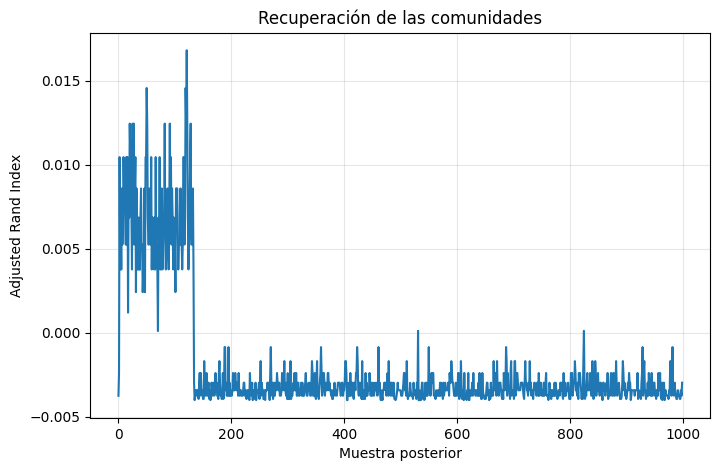

In [19]:
# PROBLEMA DE LABEL SWITCHING
# IMPORTANTE:
# El Gibbs sampler no sabe que nuestra comunidad "0"
# es la comunidad "0" verdadera.
# Puede encontrar exactamente la misma partición pero
# intercambiando las etiquetas.
# Por ejemplo:
# verdad:
#       0 0 0 1 1 1 2 2 2
# MCMC:
#       2 2 2 0 0 0 1 1 1
# Estadísticamente son la misma partición.
# Para medir recuperación de comunidades usamos
# Adjusted Rand Index (ARI), que no depende de las etiquetas.
ARI_samples = []
for Z_sample in Z_samples:
    ari = adjusted_rand_score(Z_true.flatten(), Z_sample.flatten())
    ARI_samples.append(ari)
mean_ARI = np.mean(ARI_samples)
print()
print("======================================")
print("RECUPERACIÓN DE COMUNIDADES")
print("======================================")
print(f"ARI promedio = {mean_ARI:.3f}")
# 21. EVOLUCIÓN DEL ARI
plt.figure(figsize=(8,5))
plt.plot(ARI_samples)
plt.xlabel("Muestra posterior")
plt.ylabel("Adjusted Rand Index")
plt.title("Recuperación de las comunidades")
plt.grid(alpha=0.3)
plt.show()

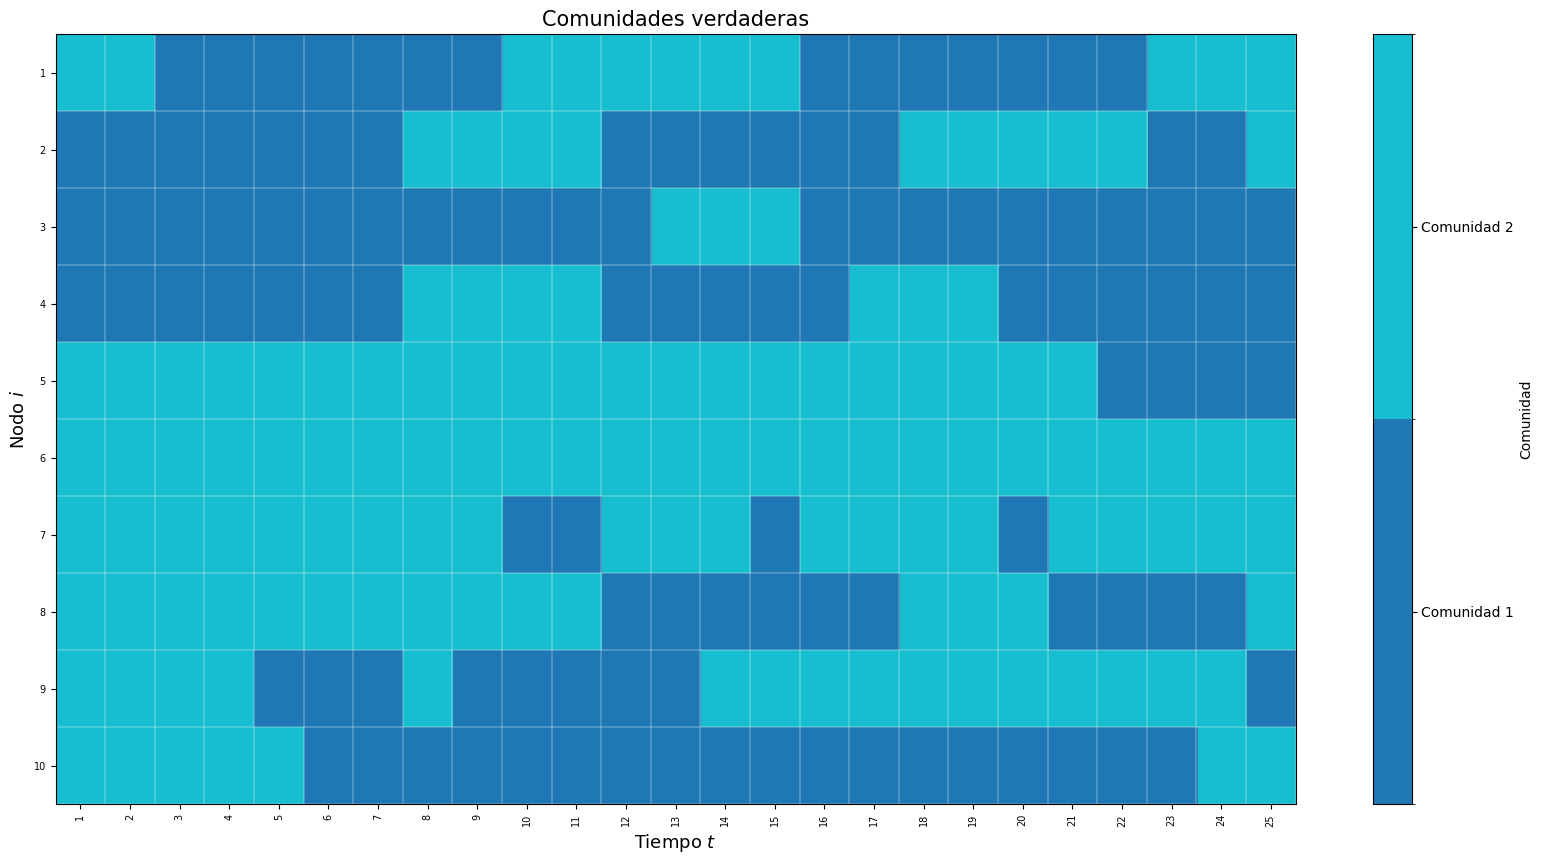

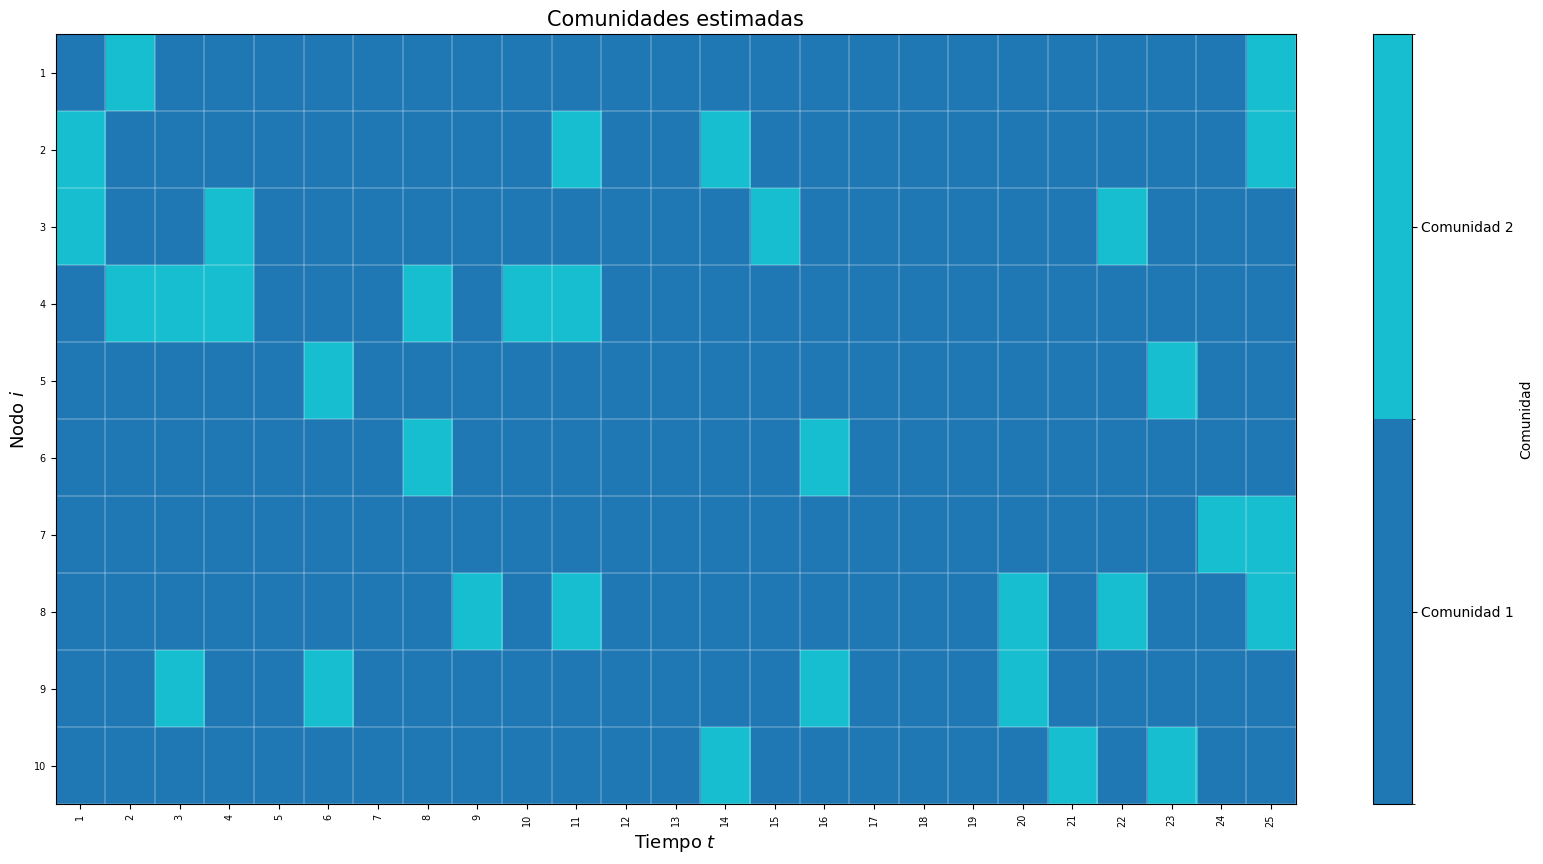

In [20]:

plot_community_evolution(
    Z_true,
    title="Comunidades verdaderas"
)

plot_community_evolution(
    Z_estimated,
    title="Comunidades estimadas"
)